<a href="https://colab.research.google.com/github/aminrafi394/ai-second-project/blob/Part_One_3_4_5/Part_One_4_5_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**در این بخش کتبخانه های مورد نیاز را وارد می کنیم**

In [107]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


**در این بخش شروع به خواندن داده ها می کنیم**

In [108]:
from google.colab import drive


drive.mount('/content/drive')
path_train = '/content/drive/MyDrive/train_data.csv'
train_data = pd.read_csv(path_train)

path_test = '/content/drive/MyDrive/test_data.csv'
test_data = pd.read_csv(path_test)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


/tmp/ipykernel_1320/2519574598.py:6: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  train_data = pd.read_csv(path_train)


In [109]:
train_data.head(10)

,overall,vote,verified,reviewTime,reviewerID,asin,style,reviewerName,reviewText,summary,unixReviewTime
0,2,NaN,False,2016-11-11,A2OSUEZJIN7BI,0511189877,NaN,Chris,I have an older URC-WR7 remote and thought thi...,Cannot Learn,1478822400
1,5,NaN,True,2016-06-06,A2NETQRG6JHIG7,0511189877,NaN,Qrysta White,First time I've EVER had a remote that needed ...,zero programming needed! Miracle!?,1465171200
2,4,NaN,True,2016-03-10,A12JHGROAX49G7,0511189877,NaN,Linwood,Got them and only 2 of them worked. company ca...,Works Good and programs easy.,1457568000
3,5,NaN,True,2016-01-14,A1KV65E2TMMG6F,0511189877,NaN,Dane Williams,I got tired of the remote being on the wrong s...,Same as TWC remote,1452729600
4,5,NaN,True,2016-10-20,A280POPEWI0NSA,0594459451,NaN,Kristina H.,After purchasing cheap cords from another webs...,Good Quality Cord,1476921600
5,5,NaN,True,2016-06-18,A2KTAT1Y3VRVSJ,0594459451,NaN,MnMMom3,This is a great charging cable for the Nook. ...,Better than original charger!,1466208000
6,5,NaN,True,2016-02-11,A1CHTT6E3NV5YL,0594459451,NaN,Amazon Shopper,The 90 degree connector is a bonus that allows...,Works great on my Wife's older model Nook Color.,1455148800
7,2,NaN,True,2016-04-02,A1TI6WQ69ST707,0594481902,NaN,kyle,I bought this thinking it would be a great rep...,Good enough to charge and wipe an older nook b...,1459555200
8,4,NaN,True,2016-01-10,A38NYFVE0FCZRG,0594481902,NaN,S. Artist,It works! I was skeptical about ordering it b...,"It works, but it costs $30! Generic USB wall ...",1452384000
9,5,NaN,True,2016-09-19,A2LLAAYS88V96P,0594296420,NaN,Tabatha,Brand name adapter this is just like the one y...,Brand name adapter this is just like the one y...,1474243200


In [110]:
test_data.head(10)

,vote,verified,reviewTime,reviewerID,asin,style,reviewerName,reviewText,summary,unixReviewTime
0,NaN,True,2018-06-04,A20GGWE66JW9X2,B006Z394GM,{'Color:': ' FPS01-C'},Brian C Toner,The name and description of this device are mi...,The prize for most useless invention of all ti...,1528070400
1,NaN,True,2018-02-18,ARYJWXHEYHG9M,B005BE058W,"{'Size:': ' 1000W', 'Style:': ' G2'}",Snake,One of the molex connectors on the power suppl...,MELTED MOLEX CONNECTOR,1518912000
2,NaN,True,2018-01-20,A10LHZ7WFZ7HLL,B01DA0YCNC,NaN,Amazon Customer,Remote constantly disconnects/ Roku player fre...,Bricked on the regular,1516406400
3,NaN,True,2018-06-25,A11VN8EOHNLP72,B00FBJ4KYC,NaN,Jeremy Bray,I purchased this 4 year protection plan for a ...,DO NOT BUY!!!,1529884800
4,3.0,True,2016-08-17,A194Y8P8TVT7P9,B00P7G82TS,NaN,Mark,I bought one of these and have regretted it ev...,Nightmare - don't buy,1471392000
5,NaN,True,2017-09-15,ACZDN5A7ZH6RM,B006FKAZ36,{'Size:': ' 100 Feet'},Dj Breaz,Item came in with good timing. I went to use t...,Good Feel But Did Not Work.,1505433600
6,NaN,True,2016-06-27,A3K4C1O8X5HCQQ,B00KHRSGO8,{'Color:': ' White'},jachansen,I'm returning mine. I used the VGA port to go ...,Maybe you'll have better luck,1466985600
7,NaN,True,2016-10-31,AACVNY9PBN3VN,B01DOB6YW4,NaN,Sahil P,"It claims to be 128GB, Only Reads 119GB. Fake ...",Very Sad.,1477872000
8,NaN,True,2016-07-07,A3Q1AR7PVTFRSM,B01CZPJRW4,NaN,Bigbillyt,"These cables are the wrong thing, the 4 pin mo...","Sorry, I incorrectly mixed up my review for a ...",1467849600
9,2.0,True,2016-03-14,A2ZW2AF10TCKR1,B00I0FI838,{'Size:': ' 6 x 9 Inches'},Craig&#039;s Garage,"Smaller magnet than many similar products, poo...",Cheap budget speakers with poor mounting hardw...,1457913600


# Q 4

In [111]:
copy_train = train_data.copy()

**در این بخش یک ستون جدید ستون جدید ایجاد شده که با استفاده از آن تعداد واژه های درون هر پیام مشخص بشود  
سپس در مرحله بعد با حذف داده هایی که پر نشده اند و با استفاده از چارک ها یک ماسک بولی ساخته می شود تا داده های پرت در نظر گرفته نشوند**

In [112]:
target_column = copy_train[["reviewText"]]
target_column["reviewTextLength"] = copy_train["reviewText"].agg(
    lambda x : len(list(x.split(" ")))
)
target_column

/tmp/ipykernel_1320/4166783402.py:2: FutureWarning: using <function <lambda> at 0x794559f91760> in Series.agg cannot aggregate and has been deprecated. Use Series.transform to keep behavior unchanged.
  target_column["reviewTextLength"] = copy_train["reviewText"].agg(
/tmp/ipykernel_1320/4166783402.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  target_column["reviewTextLength"] = copy_train["reviewText"].agg(


,reviewText,reviewTextLength
0,I have an older URC-WR7 remote and thought thi...,113
1,First time I've EVER had a remote that needed ...,89
2,Got them and only 2 of them worked. company ca...,42
3,I got tired of the remote being on the wrong s...,62
4,After purchasing cheap cords from another webs...,49
...,...,...
838939,These are my favorite charging cords for a few...,51
838940,"Update....after 2 months of gentle use, cable ...",37
838941,These are okay. The connection becomes very if...,42
838942,"Ok here is an odd thing that happened to me, I...",111


In [113]:
before_procces_lines: int = len(target_column)

target_column = target_column.dropna()

after_remove_line: int = len(target_column)

print(f"Removed line {before_procces_lines - after_remove_line}")


Removed line 0


**در این بخش نمودار هستوگرام داده های طول نظرات به صورت طبیعی و بدون در نظر گرفتن داده های پرت و دارای تعداد کم رسم می شود در این حالت برای مشخص کردن تعداد ستون های بهینه با استفاده از حلقه تعداد از ۲۰ تا ۵۰ در نظر گرفته می شود**

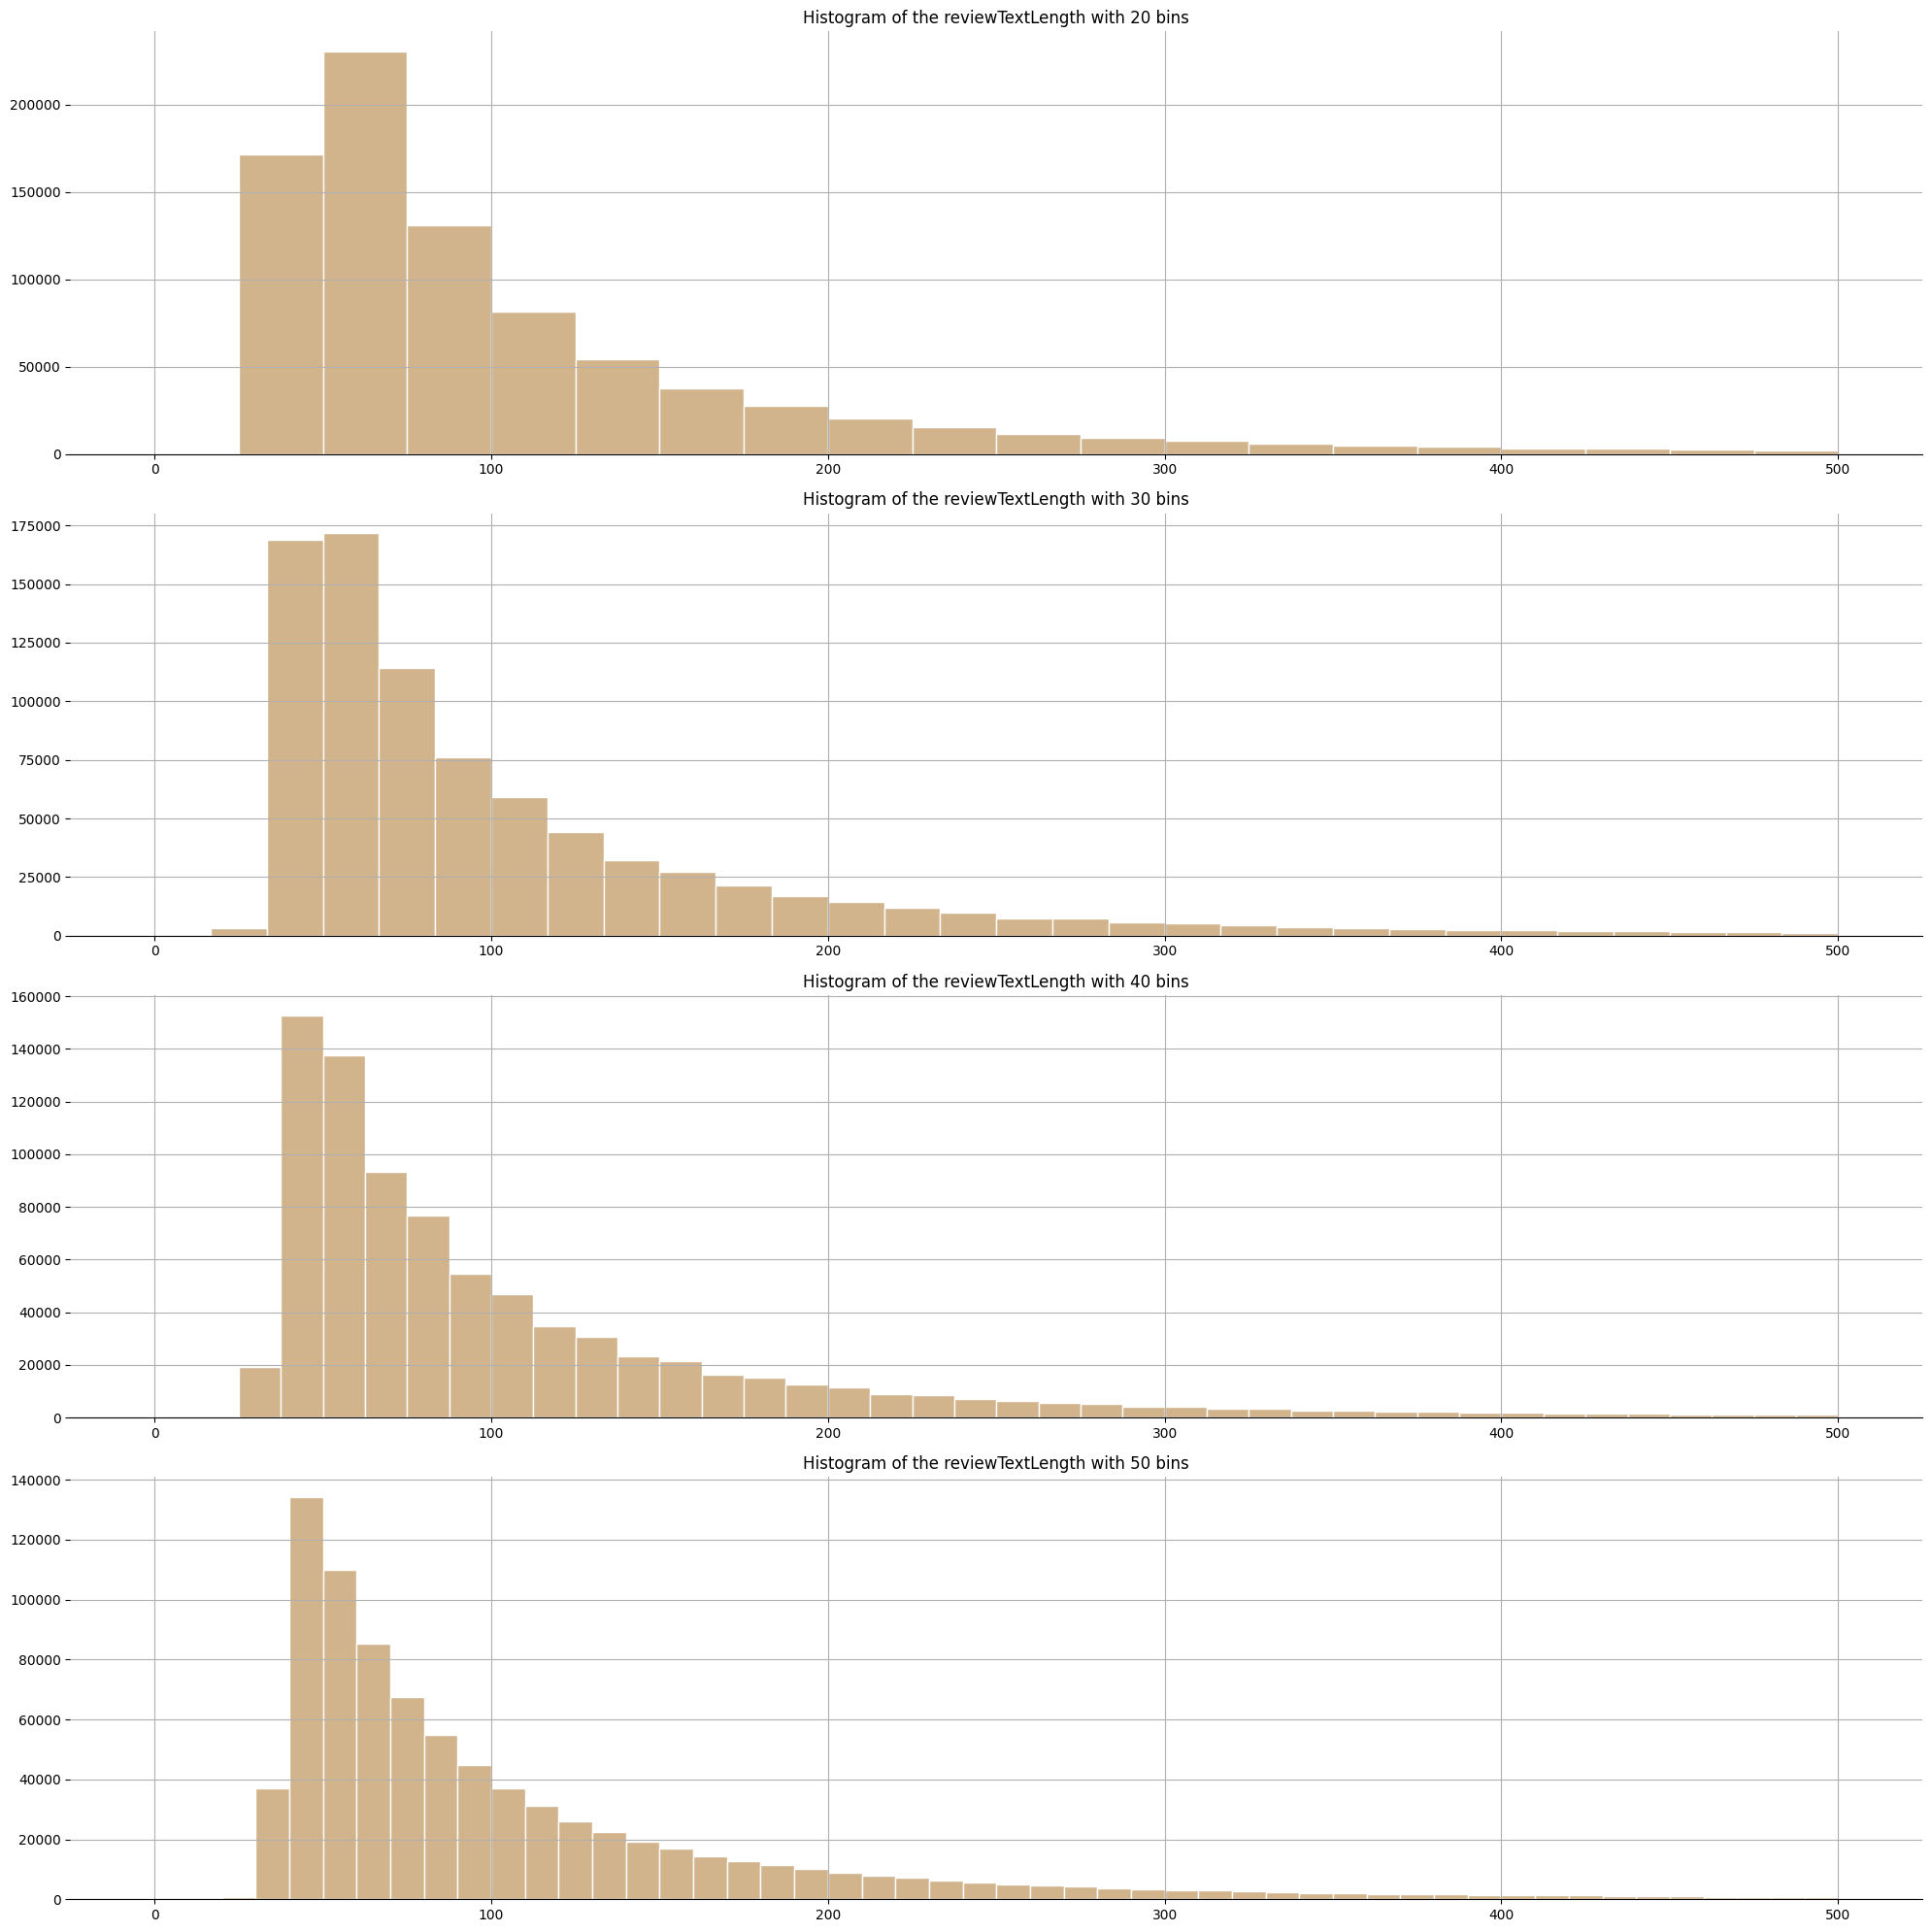

In [114]:
figure, axes = plt.subplots(4, 1, figsize=(20, 20))

flattern_axes = axes.flatten()

for ax, bin_count in zip(flattern_axes, [20, 30, 40, 50]):
  ax.spines["top"].set_visible(False)
  ax.spines["left"].set_visible(False)
  ax.spines["right"].set_visible(False)

  ax.hist(target_column["reviewTextLength"], bins=bin_count, edgecolor="white", color="tan", range=(0, 500))
  ax.set_title(f"Histogram of the reviewTextLength with {bin_count} bins")
  ax.grid()

plt.tight_layout()



In [115]:
from sklearn.preprocessing import FunctionTransformer

before_procces_lines: int = len(target_column)

def remove_length_outliers(data_frame: pd.DataFrame):
  quantile_first: int = data_frame["reviewTextLength"].quantile(0.25)
  quantile_second: int = data_frame["reviewTextLength"].quantile(0.75)

  data_frame = data_frame[(data_frame["reviewTextLength"] >= quantile_first) & (data_frame["reviewTextLength"] <= quantile_second)]

  return data_frame

remover_length = FunctionTransformer(remove_length_outliers)
target_column = remover_length.transform(target_column)

after_remove_line: int = len(target_column)

print(f"Removed line {before_procces_lines - after_remove_line} as outliers")
target_column

Removed line 416801 as outliers


,reviewText,reviewTextLength
0,I have an older URC-WR7 remote and thought thi...,113
1,First time I've EVER had a remote that needed ...,89
3,I got tired of the remote being on the wrong s...,62
5,This is a great charging cable for the Nook. ...,57
8,It works! I was skeptical about ordering it b...,128
...,...,...
838934,Some other buyers complained about not having ...,75
838936,EDIT: because the N1 is no longer offered by V...,76
838938,Fits the old cordless phones just fine and wor...,80
838942,"Ok here is an odd thing that happened to me, I...",111


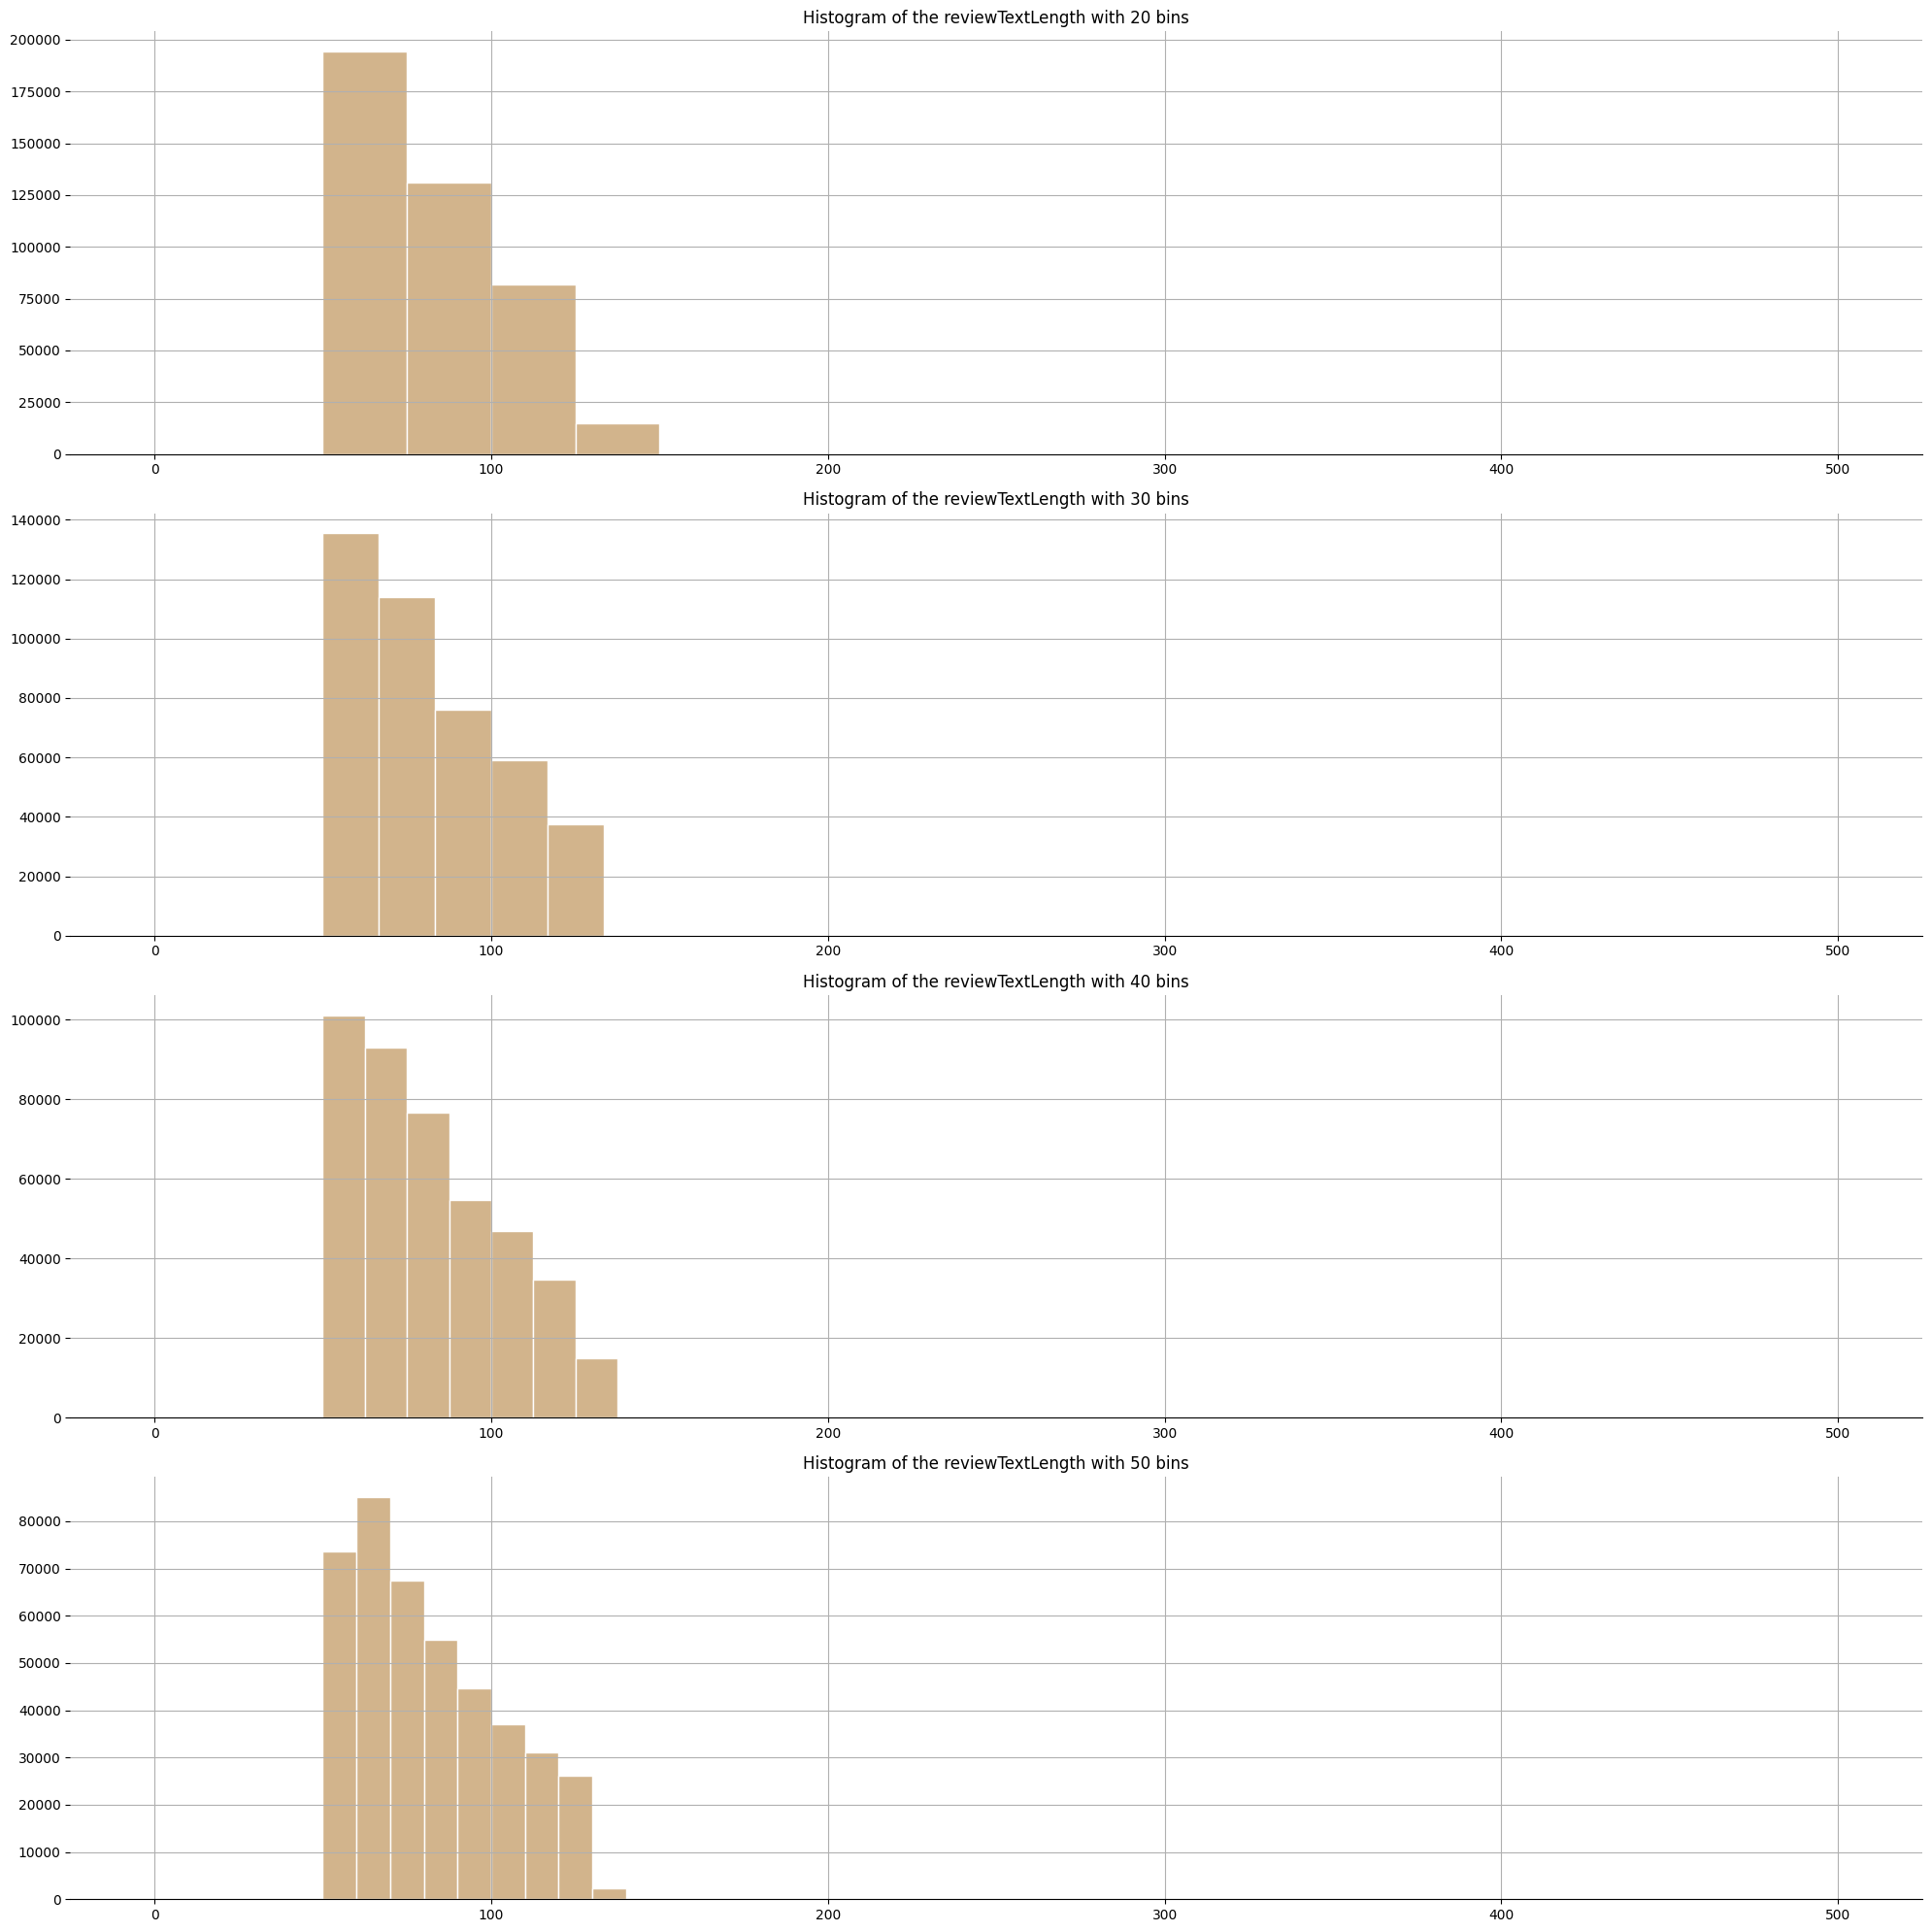

In [116]:
figure, axes = plt.subplots(4, 1, figsize=(20, 20))

flattern_axes = axes.flatten()

for ax, bin_count in zip(flattern_axes, [20, 30, 40, 50]):
  ax.spines["top"].set_visible(False)
  ax.spines["left"].set_visible(False)
  ax.spines["right"].set_visible(False)

  ax.hist(target_column["reviewTextLength"], bins=bin_count, edgecolor="white", color="tan", range=(0, 500))
  ax.set_title(f"Histogram of the reviewTextLength with {bin_count} bins")
  ax.grid()

plt.tight_layout()



**مشاهده می شود که در بین داده ها  
پیش از زمان خذف داده های پرت تعداد واژه های نظرات به بیش از ۴۰۰ و ۵۰۰ می رسید و نمودار یه چولگی بسیار بدی داشت  و تجمع اکثریت در بین داده های بین مثلا ۵۰ تا ۲۰۰ بود بنابرین طبق نمودار ها رسم شده برای خونایی بهتر تعداد ستون ها به ۴۰ و تعداد این بازه از ۵۰ تا ۲۰۰ انتخاب می شود تا داده های موثر و تراکم بالا در نظر گرفته بشوند.**

# Q 5

**در این بخش ابتدا از داده یک کپی می گیریم. سپس داده های با امتیاز ۵ را جداسازی کرده و با استفاده از تابع شمارش برداشته و در نهایت حواب تحویل داده می شود**

In [117]:
copy_data = train_data.copy()


In [118]:
copy_data.dtypes

,0
overall,int64
vote,object
verified,bool
reviewTime,object
reviewerID,object
asin,object
style,object
reviewerName,object
reviewText,object
summary,object


In [119]:
copy_data = copy_data.dropna()

In [120]:
copy_data = copy_data[copy_data["overall"] == 5]

copy_data

,overall,vote,verified,reviewTime,reviewerID,asin,style,reviewerName,reviewText,summary,unixReviewTime
18,5,4.0,True,2017-02-18,A1JHNR71TPEETW,073530498X,{'Format:': ' Spiral-bound'},Amazon Customer,I bought this to display some vintage photos t...,Great way to showcase vintage photos!,1487376000
19,5,2.0,True,2016-12-26,AU7SO8B4M5UBA,073530498X,{'Format:': ' Spiral-bound'},ruth,Cute! Bought 2 for my daughter. I thought it w...,They are nice.,1482710400
45,5,10.0,True,2016-03-26,AHQ63IBAOCUC6,1059844575,{'Color:': ' Black'},javibarr,I had given this item a 1 star and bad review ...,If you want it to work properly Read This!!,1458950400
46,5,4.0,True,2016-03-17,A21JOU9DTCR6WS,1059844575,{'Color:': ' Black'},Daniel Baker,Works just fine for LG G4.\nI think it should ...,Works just fine for LG G4.,1458172800
67,5,2.0,True,2016-02-10,AXLHMG77HZ7BJ,1464120153,{'Format:': ' Misc. Supplies'},Anthony megalizzi,I needed this iClicker for a college class and...,... iClicker for a college class and it works ...,1455062400
...,...,...,...,...,...,...,...,...,...,...,...
838612,5,3.0,True,2017-04-27,A2NLL1FJFW8HBF,B01HDXX3MS,{'Color:': ' Pink with Polkadots'},Miranda,"Great design. Pretty loud. Not too bulky, and ...",Great design. Pretty loud,1493251200
838643,5,3.0,True,2018-02-01,A1PO7VBPAVGM1N,B01HEF8OV0,{'Capacity:': ' 10TB'},heraldo,10TB model review. HGST are makers of the best...,Super reliable! Quiet enough for me.,1517443200
838667,5,2.0,True,2018-05-03,A2D4WD6GRBHZ2E,B01HEQJGRU,{'Color:': ' Silver'},beatcomber,I purchased this specifically for doing vinyl ...,Great for impedance matching the record output...,1525305600
838797,5,2.0,False,2016-07-31,A1LFQEQNMBWRZ2,B01HGKPJJ8,{'Color:': ' Charcoal'},The Organic Millennial,The problem Ive been having is finding a way t...,Solution to stick your phone anwhere!,1469923200


In [124]:
target_frame = copy_data.copy()
target_frame = target_frame.groupby(["asin"]).size()
target_frame = target_frame.sort_values(ascending=False)
target_frame = target_frame.head(10)

target_frame

,0
asin,
B00S9SGNNS,105
B01A7G35S0,101
B009ZGK6QS,95
B003Y5RYNY,86
B01DUTOI5U,86
B00Y01VRSO,83
B01E3SNO3E,81
B01DXVKQEW,75
B00LV8YZLK,69


**با داشتن این شناسه محصولات حالا باید یه تابغ نوشته بشه تا با ارسال در خواست و گرفتن پاسخ بتونیم به اسم برند و شناسه محصول دسترسی داشته باشیم**

In [125]:
import requests
from bs4 import BeautifulSoup

def fetch_product_details(asin):
    url = f"https://www.amazon.com/dp/{asin}"
    try:
        response = requests.get(url, timeout=10)
        if response.status_code != 200:
            return pd.Series(["Unknown", "Unknown"])

        soup = BeautifulSoup(response.content, "html.parser")

        title_el = soup.find("span", id="productTitle")
        title = title_el.get_text(strip=True) if title_el else "Unknown"

        brand_el = soup.find("a", id="bylineInfo")
        if not brand_el:
            brand_el = soup.find("tr", class_="po-brand")

        brand = brand_el.get_text(strip=True) if brand_el else "Unknown"

        brand = (
            brand.replace("Brand:", "")
            .replace("Visit the", "")
            .replace("Store", "")
            .strip()
        )

        return pd.Series([brand, title])
    except Exception as e:
        return pd.Series([f"{e}", f"{e}"])





In [126]:
target_frame = target_frame.reset_index()
target_frame[["brand", "title"]] = target_frame["asin"].apply(
    fetch_product_details
)
target_frame = target_frame.rename(columns={0: "vote_count"})
target_frame

,asin,five_star_count,brand,title
0,B00S9SGNNS,105,BrandASUS,"ASUS AC3200 Tri-Band Gigabit WiFi Router, AiPr..."
1,B01A7G35S0,101,1MORE,1MORE Triple Driver in-Ear Earphones Hi-Res He...
2,B009ZGK6QS,95,Bafx Products,BAFX Products (Infrared) IR Remote Control Ext...
3,B003Y5RYNY,86,TP-Link,TP-Link N450 WiFi Router - Wireless Internet R...
4,B01DUTOI5U,86,Samsung,Samsung UN43KU6300 43-Inch 4K Ultra HD Smart L...
5,B00Y01VRSO,83,eero,eero Home WiFi System (Individual) - 1st Gener...
6,B01E3SNO3E,81,BrandBose,Bose QuietComfort 35 (Series I) Wireless Headp...
7,B01DXVKQEW,75,BrandSamsung,"Samsung Galaxy Tab S2 SM-T813NZWEXAR 32GB 9.7""..."
8,B00LV8YZLK,69,Ubiquiti Networks,"Ubiquiti Unifi Security Appliance (USG), Singl..."
9,B00V49LNCU,68,BrandSamsung,Samsung Galaxy Tab A 8 Inch; 16 GB Wifi Tablet...


## Q 6

In [127]:
print("Amir")

Amir
